# 01 — EDA: TrashNet (dataset-resized)

Exploration of the local dataset after `scripts/download_data.py` i `scripts/prepare_split.py`.

**Goal:** class counts, resolutions, corrupt files, train/val/test split, sample images and short conclusions for training.

In [1]:
from __future__ import annotations

import json
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from PIL import Image

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from sortwise.config import CLASS_LABELS, CLASS_NAMES, DATASET_DIR, MANIFEST_PATH, SPLITS_DIR

print("ROOT:", ROOT)
print("DATASET:", DATASET_DIR)
print("exists:", DATASET_DIR.is_dir())

ROOT: C:\Users\gabry\Desktop\Portfolio\explainable-image-classifier
DATASET: C:\Users\gabry\Desktop\Portfolio\explainable-image-classifier\data\raw\dataset-resized
exists: True


In [2]:
manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
files = pd.DataFrame(manifest["files"])
print("num_files:", manifest["num_files"])
print("corrupt:", len(manifest.get("corrupt_files", [])))
display(files.head())

num_files: 2527
corrupt: 0


,id,path,class,size_bytes,sha256,ok,width,height,mode,error
0,cardboard/cardboard1.jpg,cardboard/cardboard1.jpg,cardboard,17333,9573fd98a5aca2ab9a4c5b9ebcdfa4dcf9719b216c2025...,True,512,384,RGB,None
1,cardboard/cardboard10.jpg,cardboard/cardboard10.jpg,cardboard,21683,f460e7a993aabafef6839fa1fce1034c40713411beff32...,True,512,384,RGB,None
2,cardboard/cardboard100.jpg,cardboard/cardboard100.jpg,cardboard,14884,13277fa7ae788f6f342a7d41ada36d4adcd20c58e504f2...,True,512,384,RGB,None
3,cardboard/cardboard101.jpg,cardboard/cardboard101.jpg,cardboard,14289,2f3dafed35830c61c3464c876f7cfb82ad3b635078f630...,True,512,384,RGB,None
4,cardboard/cardboard102.jpg,cardboard/cardboard102.jpg,cardboard,18015,5a88bce0103f59145f02b7fc0f50aa6dc3fbf29a1ffcae...,True,512,384,RGB,None


## Class counts

,n
class,
Cardboard,403
Glass,501
Metal,410
Paper,594
Plastic,482
Other waste,137


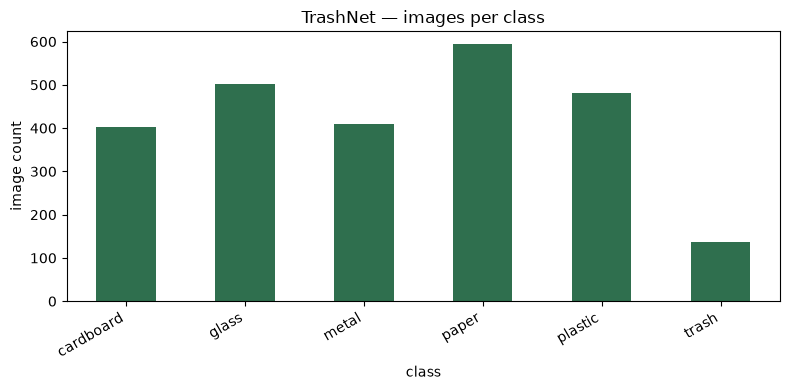

Imbalance ratio (max/min): 4.34
Note: the `trash` class is clearly smaller — macro-F1 will matter more than accuracy.


In [3]:
counts = files["class"].value_counts().reindex(CLASS_NAMES)
counts_pl = counts.rename(index=CLASS_LABELS)
display(counts_pl.to_frame("n"))

fig, ax = plt.subplots(figsize=(8, 4))
counts.plot(kind="bar", ax=ax, color="#2f6f4e")
ax.set_title("TrashNet — images per class")
ax.set_xlabel("class")
ax.set_ylabel("image count")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

print(f"Imbalance ratio (max/min): {counts.max() / counts.min():.2f}")
print("Note: the `trash` class is clearly smaller — macro-F1 will matter more than accuracy.")

## Resolutions and file integrity

usable: 2527 / corrupt: 0


,,n
width,height,
512,384,2527


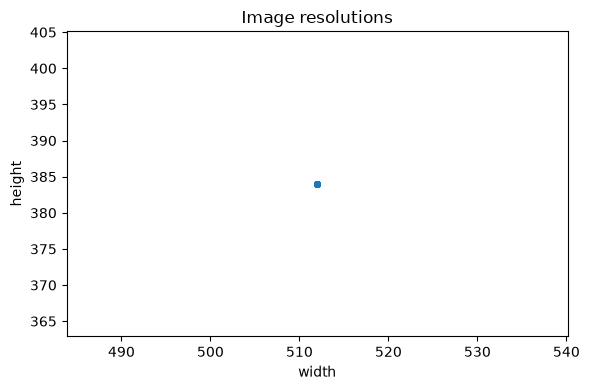

In [4]:
ok = files[files["ok"] == True].copy()
print("usable:", len(ok), "/ corrupt:", (~files["ok"]).sum())

res = ok.groupby(["width", "height"]).size().sort_values(ascending=False)
display(res.head(10).to_frame("n"))

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(ok["width"], ok["height"], alpha=0.25, s=12)
ax.set_title("Image resolutions")
ax.set_xlabel("width")
ax.set_ylabel("height")
plt.tight_layout()
plt.show()

## Train / val / test split

seed: 42
ratios: {'train': 0.7, 'val': 0.15, 'test': 0.15}
counts: {'train': 1764, 'val': 378, 'test': 379}


split,train,val,test
class,,,
cardboard,282,60,61
glass,348,75,75
metal,286,61,62
paper,416,89,89
plastic,336,72,72
trash,96,21,20


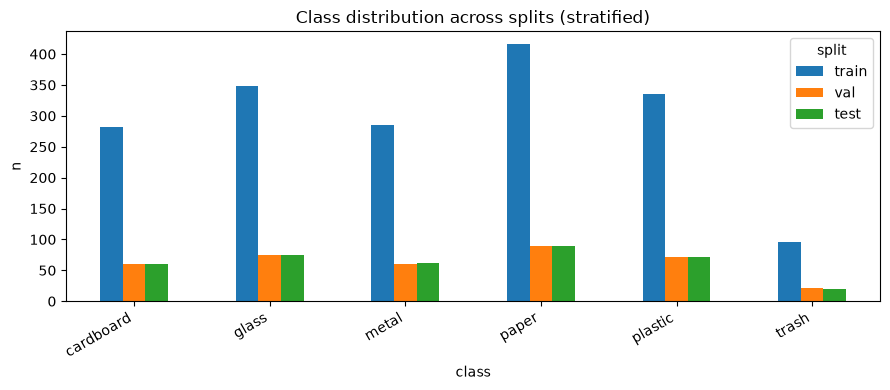

In [5]:
splits_path = SPLITS_DIR / "splits.json"
splits_doc = json.loads(splits_path.read_text(encoding="utf-8"))
print("seed:", splits_doc["seed"])
print("ratios:", splits_doc["ratios"])
print("counts:", splits_doc["counts"])

rows = []
for split_name, class_counts in splits_doc["class_counts"].items():
    for cls, n in class_counts.items():
        rows.append({"split": split_name, "class": cls, "n": n})
split_df = pd.DataFrame(rows)
pivot = split_df.pivot(index="class", columns="split", values="n").reindex(CLASS_NAMES)
pivot = pivot[["train", "val", "test"]]
display(pivot)

pivot.plot(kind="bar", figsize=(9, 4))
plt.title("Class distribution across splits (stratified)")
plt.ylabel("n")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## Sample images

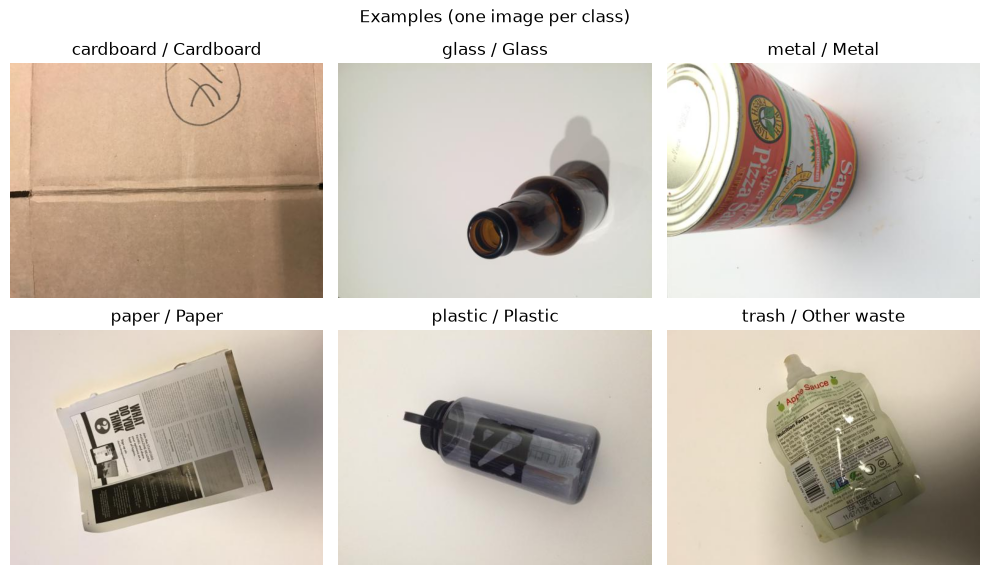

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
axes = axes.ravel()
for ax, cls in zip(axes, CLASS_NAMES):
    sample = files[files["class"] == cls].iloc[0]
    img = Image.open(DATASET_DIR / sample["path"]).convert("RGB")
    ax.imshow(img)
    ax.set_title(f"{cls} / {CLASS_LABELS[cls]}")
    ax.axis("off")
plt.suptitle("Examples (one image per class)")
plt.tight_layout()
plt.show()

## Conclusions

1. The dataset has **2527** images in **6** classes; all files decoded correctly (0 corrupt in the manifest).
2. The **`trash`** class is clearly smaller — during evaluation, report **macro-F1** and per-class metrics, not just accuracy.
3. Images come mostly from controlled conditions (light / white background) — the model may generalize worse to own photos with other backgrounds; it is worth preparing a separate test set.
4. The **70/15/15** split with seed **42** is saved in `data/processed/splits/` and should be used in all experiments (no leakage).
5. Next step: **ResNet18** baseline (head-only vs fine-tune) on CUDA and comparison with a second model.